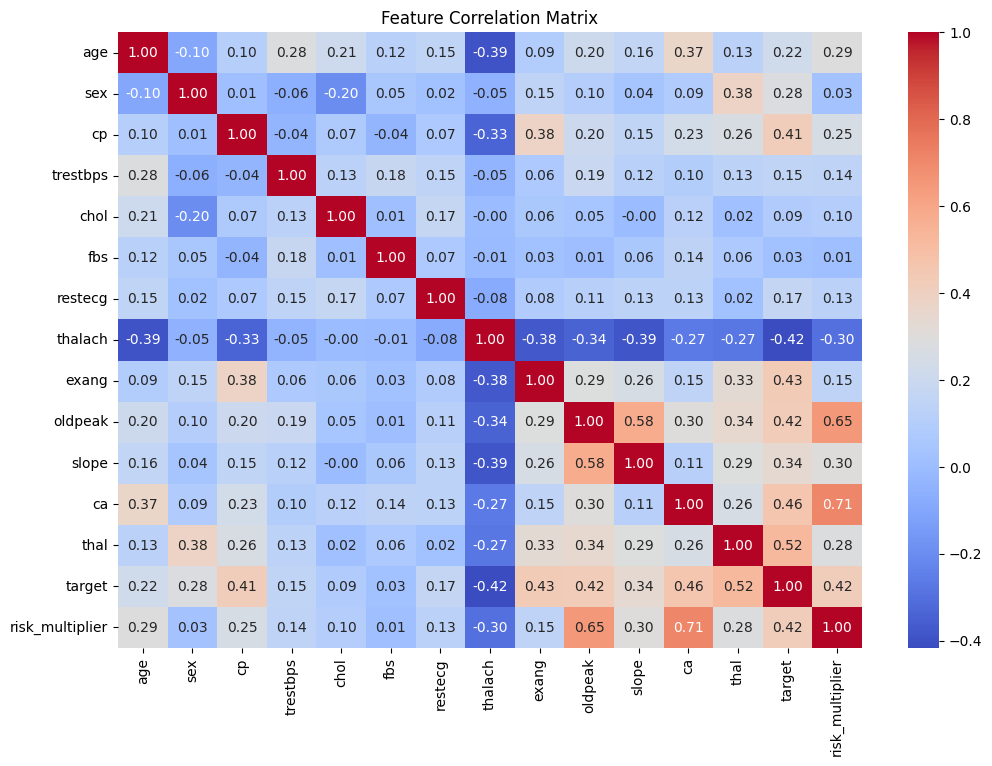


=== Random Forest ===
Accuracy: 0.9016
              precision    recall  f1-score   support

           0       0.85      0.97      0.90        29
           1       0.96      0.84      0.90        32

    accuracy                           0.90        61
   macro avg       0.91      0.90      0.90        61
weighted avg       0.91      0.90      0.90        61


=== Gradient Boosting ===
Accuracy: 0.8525
              precision    recall  f1-score   support

           0       0.79      0.93      0.86        29
           1       0.93      0.78      0.85        32

    accuracy                           0.85        61
   macro avg       0.86      0.86      0.85        61
weighted avg       0.86      0.85      0.85        61


=== KNN ===
Accuracy: 0.8852
              precision    recall  f1-score   support

           0       0.89      0.86      0.88        29
           1       0.88      0.91      0.89        32

    accuracy                           0.89        61
   macro avg  

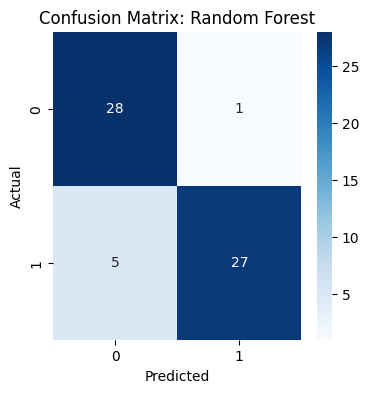

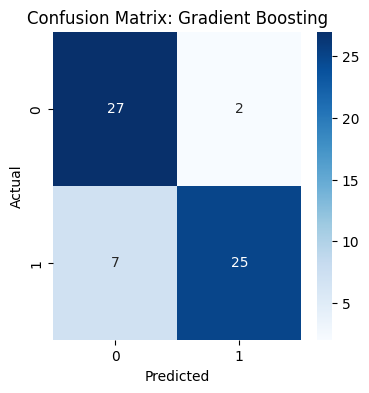

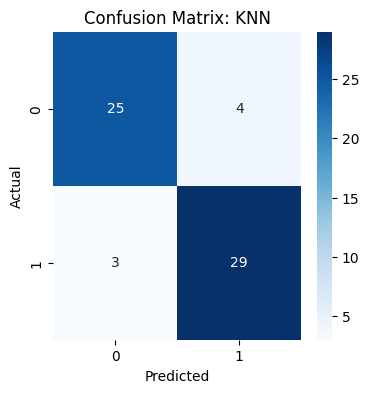

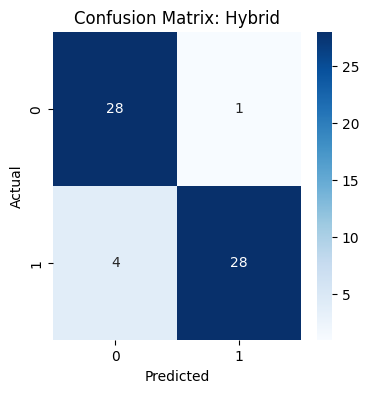


=== MODEL PERFORMANCE SUMMARY ===
               Model  Accuracy  Precision   Recall  F1 Score       AUC
0      Random Forest  0.901639   0.964286  0.84375  0.900000  0.948276
1  Gradient Boosting  0.852459   0.925926  0.78125  0.847458  0.919181
2                KNN  0.885246   0.878788  0.90625  0.892308  0.932651
3             Hybrid  0.918033   0.965517  0.87500  0.918033  0.942888


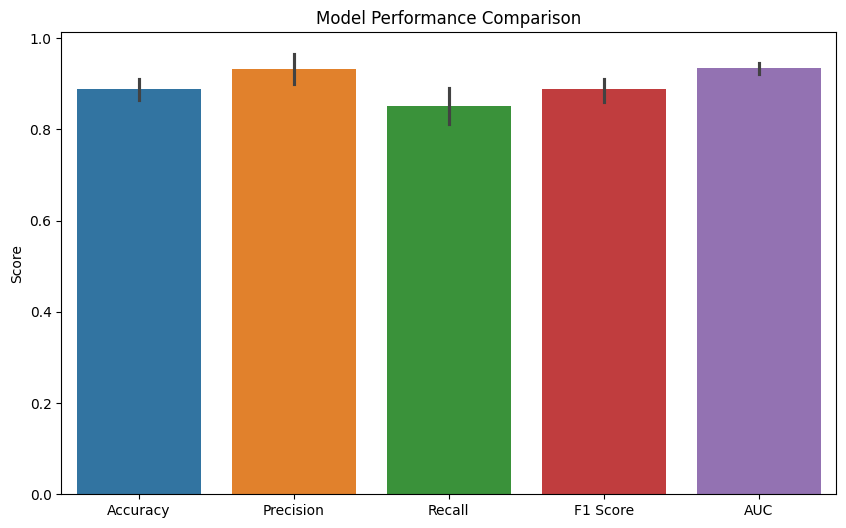

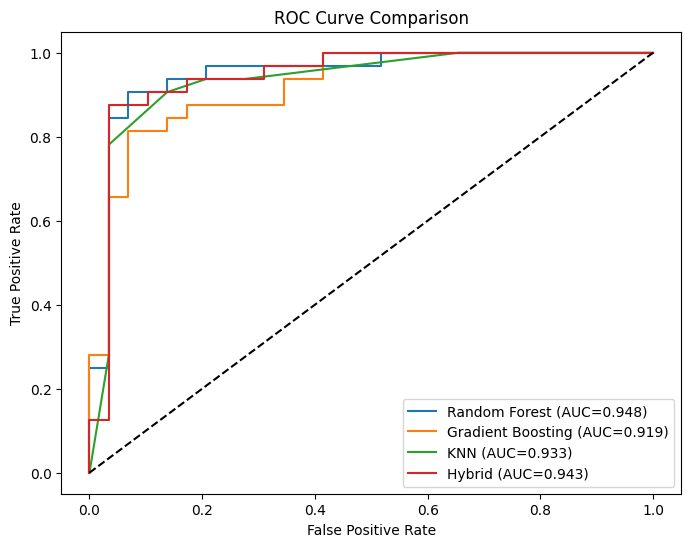

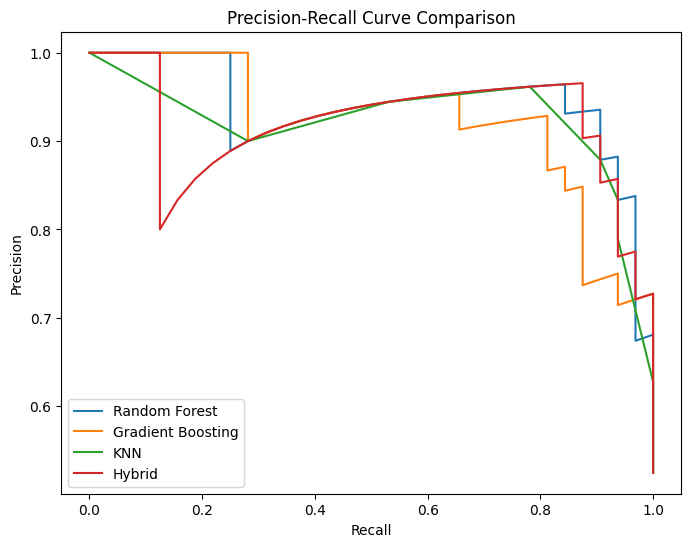

In [1]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    precision_score, recall_score, f1_score,
    roc_curve, auc, precision_recall_curve
)

# ==========================================
# 2. LOAD DATASET
# ==========================================
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

names = ['age','sex','cp','trestbps','chol','fbs','restecg',
         'thalach','exang','oldpeak','slope','ca','thal','target']

df = pd.read_csv(url, names=names, na_values="?")

# ==========================================
# 3. DATA PREPROCESSING
# ==========================================
df = df.fillna(df.median())

# Convert target to binary
df['target'] = (df['target'] > 0).astype(int)

# Feature Engineering
df['risk_multiplier'] = (df['oldpeak'] * df['ca']) + (df['age'] / (df['thalach'] + 1))

# ==========================================
# 4. FEATURE / TARGET SPLIT
# ==========================================
X = df.drop('target', axis=1)
y = df['target']

# Train test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==========================================
# 5. CORRELATION MATRIX
# ==========================================
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.show()

# ==========================================
# 6. DEFINE MODELS
# ==========================================
model_rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)

model_gb = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=4,
    random_state=42
)

model_knn = KNeighborsClassifier(n_neighbors=7)

# Hybrid stacking model
hybrid_stack = StackingClassifier(
    estimators=[
        ('rf', model_rf),
        ('gb', model_gb),
        ('knn', model_knn)
    ],
    final_estimator=LogisticRegression(),
    cv=10
)

models = {
    "Random Forest": model_rf,
    "Gradient Boosting": model_gb,
    "KNN": model_knn,
    "Hybrid": hybrid_stack
}

# ==========================================
# 7. MODEL TRAINING & EVALUATION
# ==========================================
results = []
conf_matrices = {}
roc_data = {}
pr_data = {}

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    preds = model.predict(X_test_scaled)
    proba = model.predict_proba(X_test_scaled)[:,1]

    acc = accuracy_score(y_test, preds)
    precision = precision_score(y_test, preds)
    recall = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)

    cm = confusion_matrix(y_test, preds)

    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_auc = auc(fpr, tpr)

    prec, rec, _ = precision_recall_curve(y_test, proba)

    results.append([name, acc, precision, recall, f1, roc_auc])

    conf_matrices[name] = cm
    roc_data[name] = (fpr, tpr, roc_auc)
    pr_data[name] = (prec, rec)

    print(f"\n=== {name} ===")
    print("Accuracy:", round(acc,4))
    print(classification_report(y_test, preds))

# ==========================================
# 8. CONFUSION MATRICES
# ==========================================
for name, cm in conf_matrices.items():

    plt.figure(figsize=(4,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

# ==========================================
# 9. MODEL PERFORMANCE COMPARISON
# ==========================================
metrics_df = pd.DataFrame(
    results,
    columns=["Model","Accuracy","Precision","Recall","F1 Score","AUC"]
)

print("\n=== MODEL PERFORMANCE SUMMARY ===")
print(metrics_df)

plt.figure(figsize=(10,6))

sns.barplot(data=metrics_df.set_index("Model"))

plt.title("Model Performance Comparison")
plt.ylabel("Score")

plt.show()

# ==========================================
# 10. ROC CURVE COMPARISON
# ==========================================
plt.figure(figsize=(8,6))

for name, (fpr, tpr, roc_auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")

plt.plot([0,1],[0,1],'k--')

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()

plt.show()

# ==========================================
# 11. PRECISION-RECALL CURVE
# ==========================================
plt.figure(figsize=(8,6))

for name, (prec, rec) in pr_data.items():
    plt.plot(rec, prec, label=name)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve Comparison")

plt.legend()

plt.show()